# EDA 10: cách chọn điểm neo của stay point (`li` so với `h1_mean`)

Tiếp nối `09_staypoint_thresholds.ipynb` (đo D, T bằng nhãn phương tiện). Notebook này chọn **cách đặt điểm neo** trong thuật toán stay point; việc xử lý khoảng trống (gap-stay) ở `11_gap_stay.ipynb`.

| Mục | Câu hỏi |
|---|---|
| 1 | Thuật toán mới `h1_mean` khác Li thế nào, tổng quan thay đổi bao nhiêu? |
| 2 | Lỗi tách stay có giảm không, `h1_mean` đã làm gì với từng stay của Li? |
| 3 | Có nhận nhầm thêm trên đoạn có nhãn không? |
| 4 | Địa điểm đứng đầu và từng user có bị ảnh hưởng không, chốt thuật toán nào? |

**Cách chạy.** Cần `data/processed/clean` và `data/interim/labels`. Từng mục tự import nên có thể chạy riêng. Mục 1 tính nặng: lưu kết quả từng user vào `data/interim/eda_stay_anchor_mean/`, lần sau đọc lại trong vài giây; đổi code `src/eda/stay_anchor.py` thì xoá thư mục này. Chỉ muốn đọc kết luận: xem các ô markdown, không cần chạy.

> **Giai đoạn: TUNING (sau khi chia validation / test).** Chỉ đọc **nhóm validation** (`split.val_users()`). Không dùng nhóm test (D17, D19).

## 1. Thuật toán mới `h1_mean` so với Li

**Hai thuật toán** (cùng D, T với `src/stays/detect.py` (200 m, 30 phút, A14), cùng cách gộp file và ngắt ở max gap 24 giờ (D16)):

| | `li` | `h1_mean` (đề xuất, D13) |
|---|---|---|
| Chọn neo | điểm **sớm nhất** đủ T | chạy Li trước, rồi dời neo vào **giữa** stay: điểm GPS gần nhất với **trung bình vĩ độ và trung bình kinh độ** của stay Li |
| Mở rộng | chỉ **về sau** neo | **cả hai phía** neo |
| Khi nào nhận stay mới | – | chỉ khi **không ngắn hơn** stay của Li; ngắn hơn thì giữ stay của Li |
| Tham số thêm | – | không có |

Trung bình tọa độ không dùng trọng số. Hình dưới là quỹ đạo giả lập để thấy cách làm. Các cách chọn neo khác đã thử và bỏ (kèm số đo) ghi ở D13 trong `notes/decisions.md`; code của chúng đã xoá.

**Kế hoạch đo** (mục 1–4):

| # | Câu hỏi | Trình bày |
|---|---|---|
| 1.1 | Tổng quan thay đổi bao nhiêu? | bảng 1, hình phân bố thời lượng |
| 2.1 | Lỗi tách stay có giảm không? | bảng 2 |
| 2.1 | `h1_mean` đã làm gì với từng stay của Li? | bảng 3, ví dụ thật |
| 3 | Có nhận nhầm thêm không (user validation có nhãn)? | bảng 4 |
| 4.1 | Hai địa điểm đứng đầu có đổi không? | bảng 5 |
| 4.2 | Có user nào bị ảnh hưởng xấu không? | bảng 6, hình theo user |
| 4.3 | Chốt | bảng điểm |

**Cách chạy.** `USERS = None` chạy toàn bộ nhóm validation (`split.val_users()`, D17). Lần đầu: mục 1 khoảng 30–60 phút (nếu chưa có cache `*_full.pkl`), `run_compare` vài phút. Kết quả từng user lưu ở `data/interim/eda_stay_anchor_mean/`; đổi code `stay_anchor.py` thì xoá thư mục này.

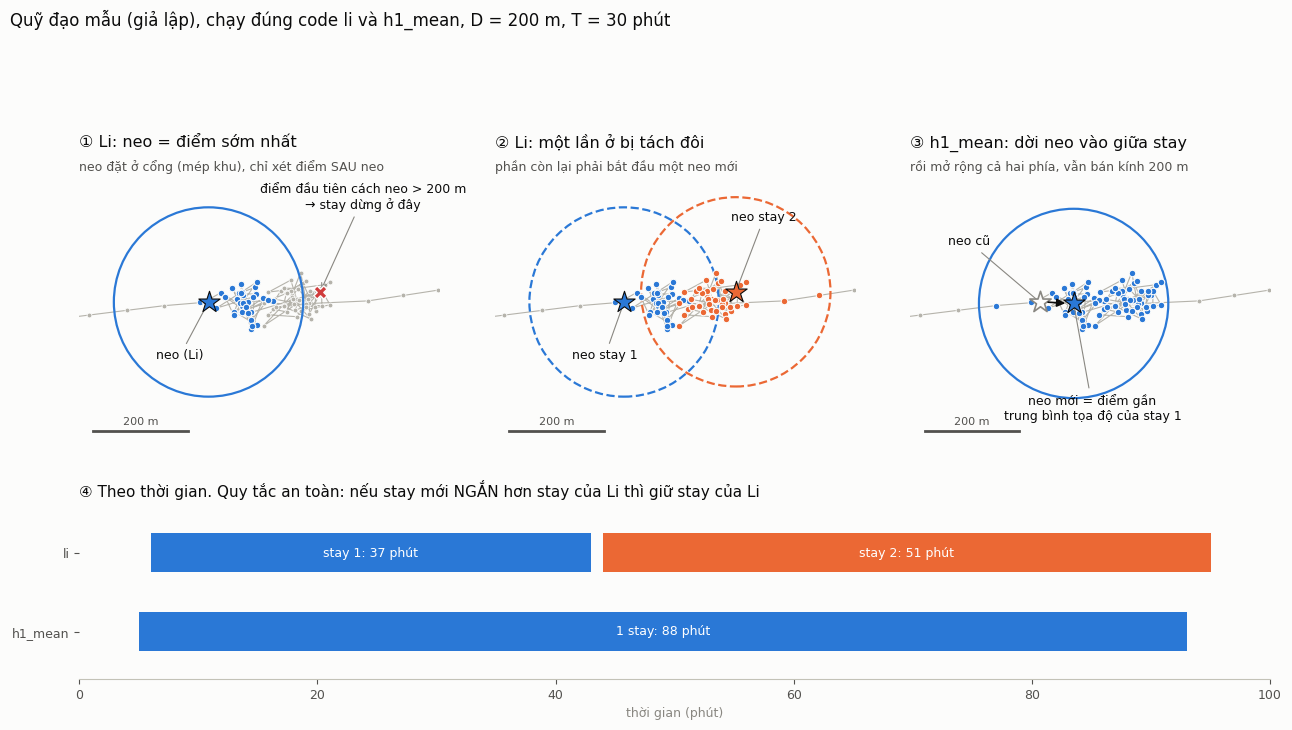

In [1]:
# chạy được ngay cả khi chưa chạy các mục trước
import importlib
from pathlib import Path
import sys
import numpy as np
import pandas as pd
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
from preprocess import interim
from eda import stay_anchor as sa
from eda import stay_anchor_plots as sp
from eda import split
importlib.reload(sa); importlib.reload(sp)
sp.demo_li_vs_h1();

### 1.1 Tổng quan

`run_users` cho chỉ số tổng hợp từng user (dùng lại kết quả đã lưu); `run_compare` lưu thêm từng stay, số đếm cách `h1_mean` xử lý stay của Li, và hai địa điểm đầu kèm giờ đêm / giờ hành chính.

79 user đã có kết quả, 36 user cần tính, 15 tiến trình
[1/36] user 029 (4 giây)
[2/36] user 043 (4 giây)
[3/36] user 112 (5 giây)
[4/36] user 008 (5 giây)
[5/36] user 014 (5 giây)
[6/36] user 001 (5 giây)
[7/36] user 180 (5 giây)
[8/36] user 023 (5 giây)
[9/36] user 130 (5 giây)
[10/36] user 081 (6 giây)
[11/36] user 159 (6 giây)
[12/36] user 114 (6 giây)
[13/36] user 095 (6 giây)
[14/36] user 005 (6 giây)
[15/36] user 078 (6 giây)
[16/36] user 123 (6 giây)
[17/36] user 056 (6 giây)
[18/36] user 061 (6 giây)
[19/36] user 063 (6 giây)
[20/36] user 080 (6 giây)
[21/36] user 175 (6 giây)
[22/36] user 166 (6 giây)
[23/36] user 057 (6 giây)
[24/36] user 164 (6 giây)
[25/36] user 171 (6 giây)
[26/36] user 075 (6 giây)
[27/36] user 132 (6 giây)
[28/36] user 142 (6 giây)
[29/36] user 083 (6 giây)
[30/36] user 062 (6 giây)
[31/36] user 039 (7 giây)
[32/36] user 013 (7 giây)
[33/36] user 020 (8 giây)
[34/36] user 163 (9 giây)
[35/36] user 035 (9 giây)
[36/36] user 167 (10 giây)
79 user đã có kết

,li,h1_mean,chênh lệch,chênh lệch (%)
số stay,11444.0,10829.0,-615.0,-5.4
tổng giờ stay,54646.9,55291.7,644.8,1.2
giờ có GPS,5380.5,5764.0,383.5,7.1
giờ khoảng trống (gap),49266.4,49527.7,261.3,0.5
"thời lượng stay, trung vị (giờ)",1.8,2.1,0.3,17.7
"thời lượng stay, p90 (giờ)",13.0,13.2,0.2,1.5
"bán kính 95% điểm, trung vị (m)",119.2,157.0,37.8,31.8


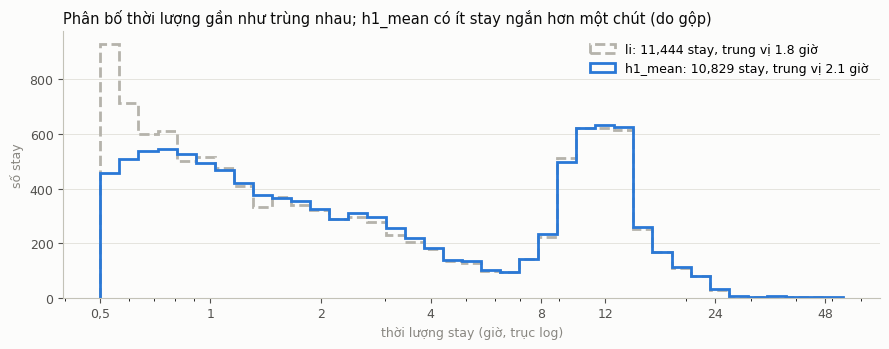

In [2]:
USERS = None      # ví dụ ["000", "001", "002"] để chạy thử nhanh

users = split.val_users()
if USERS:
    users = [u for u in users if u in set(USERS)]
S18, P18 = sa.run_users(users, sa.CMP)
CS, CH, CPL = sa.run_compare(users)

def so_sanh(rows):
    """rows: {tên chỉ số: (giá trị li, giá trị h1_mean)} → bảng li │ h1_mean │ chênh lệch │ chênh lệch %."""
    b = pd.DataFrame(rows, index=["li", "h1_mean"]).T
    b["chênh lệch"] = b["h1_mean"] - b["li"]
    b["chênh lệch (%)"] = 100 * b["chênh lệch"] / b["li"].where(b["li"] != 0)
    return b

tong = S18.groupby("variant")[["n_stays", "hours", "gps_hours", "gap_hours"]].sum()
dur = CS.groupby("variant")["dur_h"]
rad = CS.groupby("variant")["rad95_m"].median()
bang1 = so_sanh({
    "số stay": tong["n_stays"],
    "tổng giờ stay": tong["hours"],
    "  giờ có GPS": tong["gps_hours"],
    "  giờ khoảng trống (gap)": tong["gap_hours"],
    "thời lượng stay, trung vị (giờ)": dur.median(),
    "thời lượng stay, p90 (giờ)": dur.quantile(0.9),
    "bán kính 95% điểm, trung vị (m)": rad,
})
print(f"Bảng 1. Tổng quan, {S18['user'].nunique()} user")
display(bang1.round(1))
sp.duration_dist(CS);

## 2. Lỗi tách stay và cách `h1_mean` xử lý

**Stay bị tách** (`n_split`): hai stay liền nhau có tâm cách < 200 m và nghỉ < 10 phút, tức một lần ở bị cắt đôi. Đây là lỗi `h1_mean` cần sửa.

**Cách `h1_mean` xử lý mỗi stay của Li:**
- *dời neo*: stay mới (neo ở giữa, mở hai phía) không ngắn hơn, nên dùng stay mới;
- *giữ nguyên*: stay mới ngắn hơn, nên giữ stay của Li;
- *được gộp*: stay của Li đã bị stay trước (đã mở rộng) phủ hết, nên gộp vào stay trước.

In [3]:
ns = S18.pivot(index="user", columns="variant", values="n_split")
nst = S18.pivot(index="user", columns="variant", values="n_stays")
bang2 = so_sanh({
    "số cặp stay bị tách": ns.sum(),
    "stay bị tách / 100 stay": 100 * ns.sum() / nst.sum(),
    "số user có ít nhất 1 cặp bị tách": (ns > 0).sum(),
})
print("Bảng 2. Stay bị tách")
display(bang2.round(1))
d = ns["h1_mean"] - ns["li"]
print(f"Theo user: {100 * (d < 0).mean():.0f}% user giảm, {100 * (d == 0).mean():.0f}% không đổi, "
      f"{100 * (d > 0).mean():.0f}% tăng số cặp bị tách")

h = CH[["n_li", "moved", "kept", "absorbed"]].sum()
bang3 = pd.DataFrame({"số stay của Li": [h["moved"], h["kept"], h["absorbed"]]},
                     index=["dời neo (dùng stay mới)", "giữ nguyên (stay mới ngắn hơn)", "được gộp vào stay trước"])
bang3["%"] = 100 * bang3["số stay của Li"] / h["n_li"]
bang3.loc["tổng"] = [h["n_li"], 100.0]
print("Bảng 3. h1_mean đã làm gì với từng stay của Li")
display(bang3.round(1))

Bảng 2. Stay bị tách


,li,h1_mean,chênh lệch,chênh lệch (%)
số cặp stay bị tách,1095.0,578.0,-517.0,-47.2
stay bị tách / 100 stay,9.6,5.3,-4.2,-44.2
số user có ít nhất 1 cặp bị tách,80.0,68.0,-12.0,-15.0


Theo user: 58% user giảm, 40% không đổi, 2% tăng số cặp bị tách
Bảng 3. h1_mean đã làm gì với từng stay của Li


,số stay của Li,%
dời neo (dùng stay mới),9251.0,80.8
giữ nguyên (stay mới ngắn hơn),1578.0,13.8
được gộp vào stay trước,615.0,5.4
tổng,11444.0,100.0


### 2.1 Ví dụ thật

Lấy user có nhiều stay được gộp nhất, chọn một stay của `h1_mean` (dài ≤ 12 giờ) chứa trọn nhiều stay của Li nhất. Hình vẽ giống hình giả lập ở mục 1:
- **trái (Li):** mỗi màu là một stay của Li; ★ là neo (điểm đầu của stay), vòng nét đứt là 200 m quanh neo; ✕ là điểm đầu tiên cách neo hơn 200 m, nơi Li cắt stay.
- **phải (h1_mean):** ★ xanh là neo mới (điểm gần trung bình tọa độ của stay Li đầu tiên), vòng liền là 200 m quanh neo mới.
- **dưới:** cùng khoảng đó theo thời gian; ✕ là lúc Li cắt.

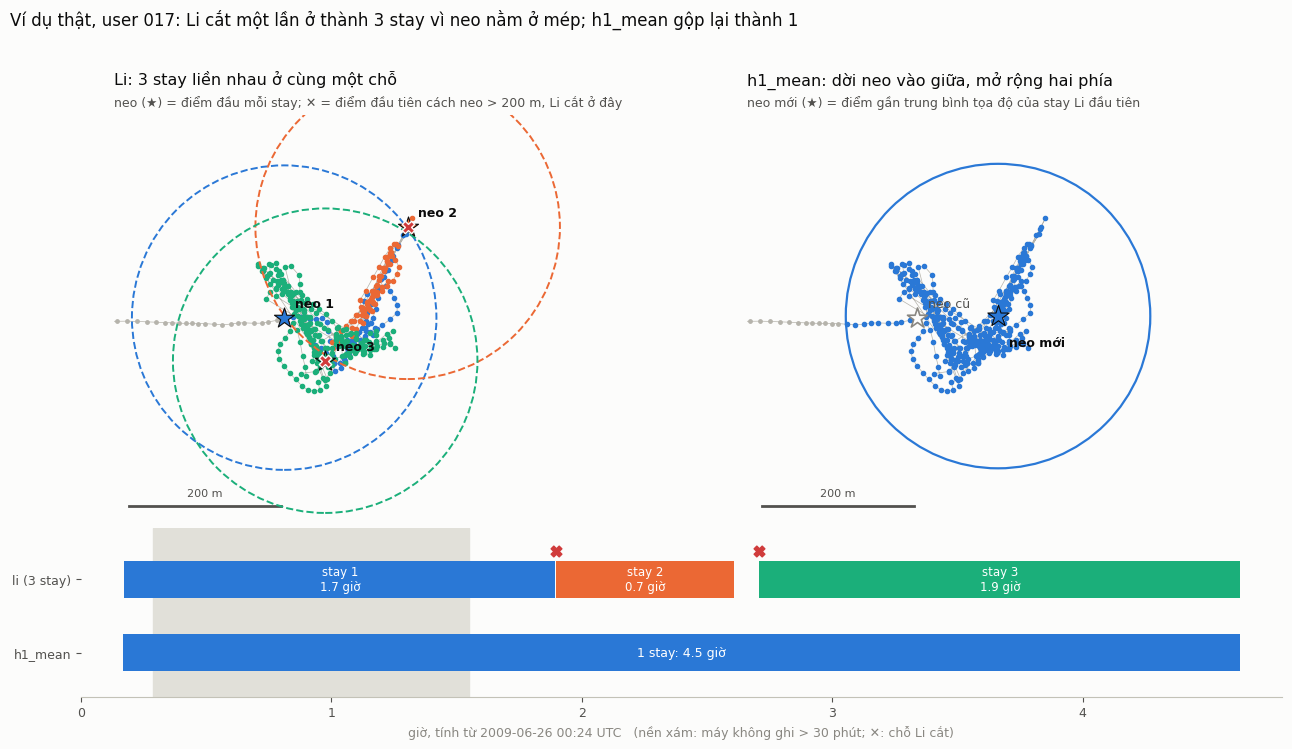

In [4]:
vi_du = CH.sort_values("absorbed", ascending=False)["user"].iloc[0]
ex = sa.merge_example(vi_du, CS)
if ex is not None:
    sp.merge_example_plot(ex);

## 3. Nhận nhầm trên đoạn có nhãn

Giống mục 2 của notebook 09 nhưng cho cả hai thuật toán: chạy chỉ trên các đoạn có nhãn **đang di chuyển** (cắt thêm ở khoảng trống > 30 phút), mọi stay tìm được là stay giả. Tách riêng `walk` (thường là đi loanh quanh trong một khu) và các loại xe (nhận nhầm thật). Hàng `li` phải khớp mục 2 của notebook 09 ở D = 200 m, T = 30 phút; không khớp thì có lỗi.

In [5]:
from eda import stay_scan as ss
label_users = ss.labeled_users()
F19 = sa.run_labels(label_users, sa.CMP)
F19 = F19[F19["variant"].isin(sa.CMP)]
XE = {"bus", "car", "taxi", "train", "subway", "airplane", "boat", "motorcycle"}
F19["nhóm"] = np.where(F19["mode"] == "walk", "walk", np.where(F19["mode"].isin(XE), "xe", "khác"))
g = F19.groupby(["variant", "nhóm"])[["hours", "false_hours"]].sum()
pct = (100 * g["false_hours"] / g["hours"]).unstack("nhóm").reindex(columns=["walk", "xe", "khác"])
t19 = F19.groupby("variant")[["hours", "false_hours", "n_false"]].sum()
bang4 = so_sanh({
    "tổng (%)": 100 * t19["false_hours"] / t19["hours"],
    "  walk (%)": pct["walk"],
    "  xe (%)": pct["xe"],
    "  khác (%)": pct["khác"],
    "stay giả / 100 giờ di chuyển": 100 * t19["n_false"] / t19["hours"],
})
bang4 = bang4.drop(columns="chênh lệch (%)").rename(columns={"chênh lệch": "chênh lệch (điểm %)"})
print(f"Bảng 4. % thời gian di chuyển có nhãn bị nhận là stay, {len(label_users)} user")
display(bang4.round(2))

[10/42] user 078 (0 giây)
[20/42] user 102 (0 giây)
[30/42] user 126 (1 giây)
[40/42] user 174 (1 giây)
[42/42] user 179 (1 giây)
Bảng 4. % thời gian di chuyển có nhãn bị nhận là stay, 42 user


,li,h1_mean,chênh lệch (điểm %)
tổng (%),10.39,11.39,1.00
walk (%),23.72,26.31,2.59
xe (%),2.82,3.02,0.19
khác (%),6.95,7.10,0.15
stay giả / 100 giờ di chuyển,13.55,12.78,-0.77


## 4. Địa điểm đứng đầu, theo từng user, và chốt

### 4.1 Hai địa điểm đứng đầu

Gom stay bằng `cluster_v1` (200 m, stay dài nhất làm tâm), so địa điểm thứ 1 và thứ 2 (theo tổng giờ) của `h1_mean` với của Li. Giờ đêm (0–6h) và giờ hành chính (thứ 2–6, 9–17h) tính theo giờ địa phương, vì bước home/office sẽ dùng chúng.

In [6]:
A = CPL[CPL["variant"] == "li"].set_index(["user", "rank"])
B = CPL[CPL["variant"] == "h1_mean"].set_index(["user", "rank"])
A, B = A.align(B, join="inner", axis=0)
lech = pd.Series(sa.haversine_m(A["lat"].to_numpy(), A["lon"].to_numpy(), B["lat"].to_numpy(), B["lon"].to_numpy()), index=A.index)
rows = []
for r in (1, 2):
    m = lech.xs(r, level="rank")
    a, b = A.xs(r, level="rank"), B.xs(r, level="rank")
    pchg = lambda c: (100 * (b[c] - a[c]) / a[c].where(a[c] > 0)).median()
    rows.append({"địa điểm": r, "số user": len(m), "tâm lệch, trung vị (m)": m.median(), "tâm lệch, p90 (m)": m.quantile(0.9),
                 "% user lệch > 100 m": 100 * (m > 100).mean(), "đổi tổng giờ, trung vị (%)": pchg("hours"),
                 "đổi giờ đêm, trung vị (%)": pchg("night_hours"), "đổi giờ hành chính, trung vị (%)": pchg("office_hours")})
bang5 = pd.DataFrame(rows).set_index("địa điểm").T
print("Bảng 5. Hai địa điểm đứng đầu: h1_mean so với li")
display(bang5.round(1))

Bảng 5. Hai địa điểm đứng đầu: h1_mean so với li


địa điểm,1,2
số user,108.0,104.0
"tâm lệch, trung vị (m)",19.7,18.5
"tâm lệch, p90 (m)",65.2,381.0
% user lệch > 100 m,7.4,15.4
"đổi tổng giờ, trung vị (%)",0.3,0.5
"đổi giờ đêm, trung vị (%)",0.0,0.1
"đổi giờ hành chính, trung vị (%)",0.3,0.2


### 4.2 Theo từng user

Tổng có thể che user bị ảnh hưởng nhiều. Bảng 6 cho phân bố thay đổi theo user; danh sách dưới là 10 user đổi tổng giờ stay nhiều nhất (nên mở bản đồ của họ nếu cần kiểm tra).

Bảng 6. Phân bố thay đổi theo user (xấu nhất: tăng số stay / giảm giờ / tăng cặp tách / lệch xa nhất)


,p10,trung vị,p90,xấu nhất
đổi số stay (%),-12.6,-3.5,0.0,0.0
đổi tổng giờ stay (%),0.1,1.0,4.7,-50.3
đổi số cặp bị tách,-11.0,-1.0,0.0,1.0
tâm địa điểm 1 lệch (m),0.0,19.7,65.2,5416.3


10 user đổi tổng giờ stay nhiều nhất


,đổi số stay (%),đổi tổng giờ stay (%),đổi số cặp bị tách,tâm địa điểm 1 lệch (m)
user,,,,
123,-9.1,-50.3,-1,114.3
019,-6.2,22.9,-2,13.0
143,-50.0,-20.7,-3,40.6
095,-5.3,20.3,0,20.1
121,-20.0,11.7,-1,36.9
138,0.0,11.0,0,56.9
006,-4.2,8.9,-1,91.6
023,-8.0,7.5,-6,0.0
177,0.0,6.6,0,17.2


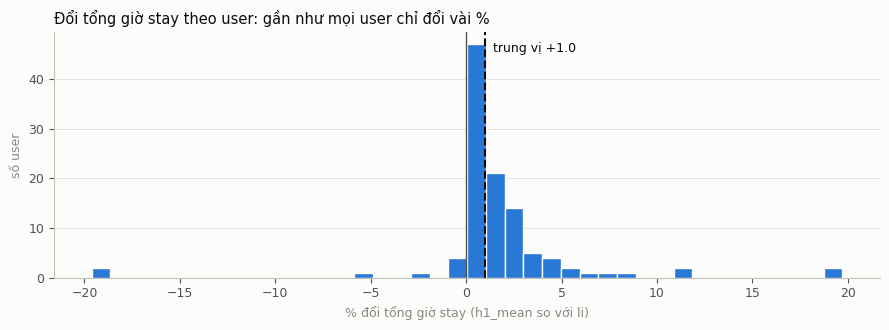

In [7]:
X = S18.pivot(index="user", columns="variant")
chg = pd.DataFrame({
    "đổi số stay (%)": 100 * (X[("n_stays", "h1_mean")] / X[("n_stays", "li")] - 1),
    "đổi tổng giờ stay (%)": 100 * (X[("hours", "h1_mean")] / X[("hours", "li")] - 1),
    "đổi số cặp bị tách": X[("n_split", "h1_mean")] - X[("n_split", "li")],
    "tâm địa điểm 1 lệch (m)": lech.xs(1, level="rank"),
})
bang6 = chg.quantile([0.1, 0.5, 0.9]).T
bang6.columns = ["p10", "trung vị", "p90"]
bang6["xấu nhất"] = [chg.iloc[:, 0].max(), chg.iloc[:, 1].min(), chg.iloc[:, 2].max(), chg.iloc[:, 3].max()]
print("Bảng 6. Phân bố thay đổi theo user (xấu nhất: tăng số stay / giảm giờ / tăng cặp tách / lệch xa nhất)")
display(bang6.round(1))
print("10 user đổi tổng giờ stay nhiều nhất")
display(chg.reindex(chg["đổi tổng giờ stay (%)"].abs().sort_values(ascending=False).index).head(10).round(1))
sp.user_change_hist(chg["đổi tổng giờ stay (%)"], "Đổi tổng giờ stay theo user: gần như mọi user chỉ đổi vài %",
                    "% đổi tổng giờ stay (h1_mean so với li)");

### 4.3 Chốt

Ba tiêu chí, mỗi tiêu chí là một câu hỏi:
1. **Một lần ở có còn bị cắt đôi không?** Stay bị tách / 100 stay (bảng 2) phải giảm (mức dùng ở ô dưới: giảm ít nhất 20%, tức tỉ lệ của `h1_mean` ≤ 0,8 lần của `li`).
2. **Có nhận nhầm lúc đang đi là ở yên không?** % thời gian di chuyển có nhãn bị nhận là stay (bảng 4) không tăng quá 1 điểm phần trăm.
3. **Nơi ở nhiều nhất có bị đổi chỗ không?** Tỉ lệ user giữ nguyên địa điểm 1 phải đủ cao (ít nhất 90%), tức tâm lệch < 100 m (bảng 5).

Hình và các dòng tóm tắt dưới đều tính từ bảng 1–6 ở trên.

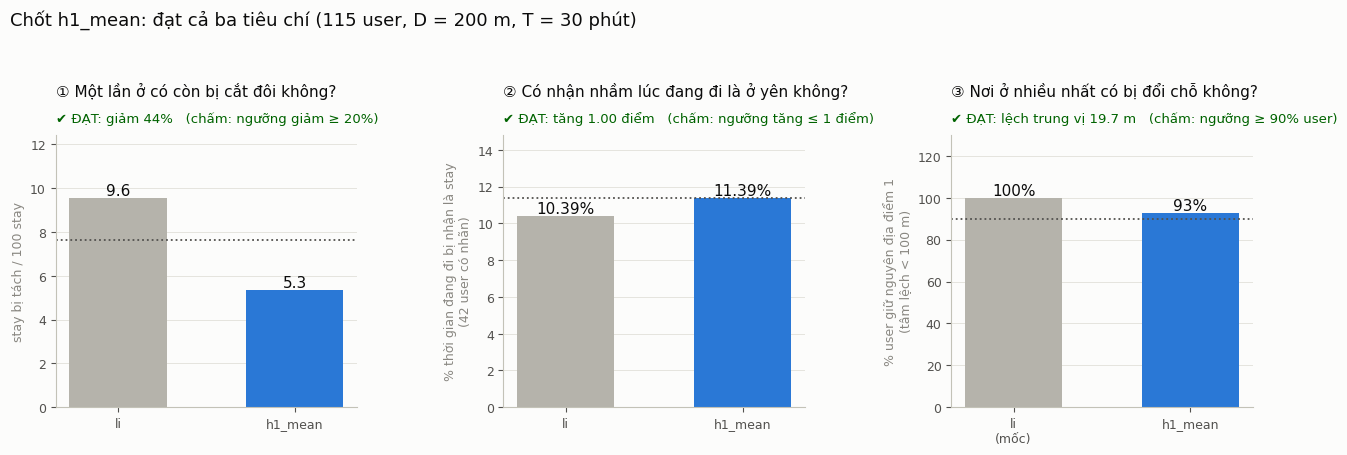

In [8]:
r95 = CS.groupby("variant")["rad95_m"].median()
m = {"n_users": S18["user"].nunique(), "n_label_users": len(label_users),
     "split_li": bang2.at["stay bị tách / 100 stay", "li"], "split_h1": bang2.at["stay bị tách / 100 stay", "h1_mean"],
     "pairs_li": int(ns["li"].sum()), "pairs_h1": int(ns["h1_mean"].sum()),
     "false_li": bang4.at["tổng (%)", "li"], "false_h1": bang4.at["tổng (%)", "h1_mean"],
     "car_li": bang4.at["  xe (%)", "li"], "car_h1": bang4.at["  xe (%)", "h1_mean"],
     "shift1": bang5.at["% user lệch > 100 m", 1], "shift2": bang5.at["% user lệch > 100 m", 2],
     "shift1_med": bang5.at["tâm lệch, trung vị (m)", 1], "shift2_med": bang5.at["tâm lệch, trung vị (m)", 2],
     "only_h1": S18.loc[S18["variant"] == "h1_mean", "hours_only_variant"].sum(),
     "only_li": S18.loc[S18["variant"] == "h1_mean", "hours_only_li"].sum(),
     "hours_li": tong.at["li", "hours"], "hours_h1": tong.at["h1_mean", "hours"],
     "rad_li": r95["li"], "rad_h1": r95["h1_mean"],
     "n_li": int(tong.at["li", "n_stays"]), "n_h1": int(tong.at["h1_mean", "n_stays"]),
     "absorbed": int(h["absorbed"]), "kept_pct": 100 * h["kept"] / h["n_li"]}
sp.scorecard(m);

In [9]:
ok = [m["split_h1"] <= 0.8 * m["split_li"], m["false_h1"] - m["false_li"] <= 1, 100 - m["shift1"] >= 90]
print(f"{m['n_users']} user. Đạt {sum(ok)}/3 tiêu chí.")
print(f"1. Stay bị tách / 100 stay: {m['split_li']:.1f} → {m['split_h1']:.1f} (giảm {100 * (1 - m['split_h1'] / m['split_li']):.0f}%; "
      f"số cặp {m['pairs_li']:,} → {m['pairs_h1']:,})  {'ĐẠT' if ok[0] else 'CHƯA ĐẠT'}")
print(f"2. Nhận nhầm tổng: {m['false_li']:.2f}% → {m['false_h1']:.2f}% ({m['false_h1'] - m['false_li']:+.2f} điểm), "
      f"xe {m['car_li']:.2f}% → {m['car_h1']:.2f}%  {'ĐẠT' if ok[1] else 'CHƯA ĐẠT'}")
print(f"3. User giữ nguyên địa điểm 1: {100 - m['shift1']:.1f}% (địa điểm 2: {100 - m['shift2']:.1f}%), "
      f"tâm lệch trung vị {m['shift1_med']:.1f} m  {'ĐẠT' if ok[2] else 'CHƯA ĐẠT'}")
print(f"Khác: tổng giờ stay {m['hours_li']:,.0f} → {m['hours_h1']:,.0f} ({100 * (m['hours_h1'] / m['hours_li'] - 1):+.1f}%), "
      f"thêm {m['only_h1']:,.0f} giờ Li bỏ sót, bỏ {m['only_li']:,.0f} giờ; số stay {m['n_li']:,} → {m['n_h1']:,}; "
      f"bán kính 95% trung vị {m['rad_li']:.0f} → {m['rad_h1']:.0f} m")

115 user. Đạt 3/3 tiêu chí.
1. Stay bị tách / 100 stay: 9.6 → 5.3 (giảm 44%; số cặp 1,095 → 578)  ĐẠT
2. Nhận nhầm tổng: 10.39% → 11.39% (+1.00 điểm), xe 2.82% → 3.02%  ĐẠT
3. User giữ nguyên địa điểm 1: 92.6% (địa điểm 2: 84.6%), tâm lệch trung vị 19.7 m  ĐẠT
Khác: tổng giờ stay 54,647 → 55,292 (+1.2%), thêm 733 giờ Li bỏ sót, bỏ 88 giờ; số stay 11,444 → 10,829; bán kính 95% trung vị 119 → 157 m


**Kết quả:** (115 user validation) `h1_mean` đạt 3/3 tiêu chí.
1. Stay bị tách / 100 stay giảm từ 9,6 xuống 5,3 (giảm 44%; số cặp bị tách 1.095 → 578). Theo user: 58% giảm, 40% không đổi, 2% tăng.
2. Nhận nhầm khi đang di chuyển tăng từ 10,39% lên 11,39% (+1,00 điểm); riêng xe từ 2,82% lên 3,02%.
3. Địa điểm 1 giữ nguyên ở 92,6% user (địa điểm 2: 84,6%), tâm lệch trung vị 19,7 m.
Các thay đổi khác: tổng giờ stay 54.647 → 55.292 (+1,2%), số stay 11.444 → 10.829, bán kính 95% trung vị 119 → 157 m. Xấu nhất theo user: user 123 mất 50,3% giờ stay, và có địa điểm 1 lệch tới 5.416 m ở một user.

**Quyết định:** giữ `h1_mean` làm cách chọn neo (D13, Duy chốt 2026-11-07). Đây là quy ước dựa trên ba tiêu chí tự đặt (mức 20%, 1 điểm, 90% là mốc mình chọn, không có điểm gãy), không phải tối ưu. Hạn chế: bán kính stay phình ra (119 → 157 m), nhận nhầm tăng 1 điểm; không có nhãn home/office để biết `h1_mean` đúng hơn (A13).